# Penguins Take Home

Reproduce the figures, tables, cleaning decisions, and models in
[the accompanying document](https://docs.google.com/document/d/1aMTChUaMZP4bzJqDUdpGow0VulTqTc4wa3gP7suz4vk/edit).
Run the cells in order. The notebook fits the models and generates the reported results
from the supplied input data. Install `requirements-notebook.txt` before running.

In [1]:
from pathlib import Path
get_ipython().run_line_magic('matplotlib', 'inline')
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / 'data/raw/shot-data.csv').exists()
)
OUTPUT = PROJECT / 'analysis/notebook_results'
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 130, 'savefig.dpi': 300,
                     'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False})

## NHL opportunity generation and conversion

The descriptive chart uses the full 2024–25 regular season at five-on-five: 424 forwards with at least 300 minutes. Attempts include blocks. The predictive comparison uses prior-season and prior-three-season histories for all skaters, with position interactions. Source snapshots contain original MoneyPuck game/season counts and NHL birth dates; rates, features, fitted models and results are calculated below.


In [2]:
from scipy.special import expit, logit
from scipy.optimize import brentq
from numpy.polynomial.hermite import hermgauss

NHL_INPUT = PROJECT / "data/notebook"
nhl_games = pd.read_csv(NHL_INPUT / "nhl_2024_player_games.csv")
nhl_games["group"] = np.where(nhl_games.position.eq("D"), "D", "F")
nhl_annual = nhl_games.groupby("player_id", as_index=False)[["minutes", "attempts", "goals"]].sum()
nhl_meta = nhl_games.groupby("player_id", as_index=False).agg(name=("name", "last"), games=("game_id", "nunique"))
nhl_roles = (nhl_games.groupby(["player_id", "group"], as_index=False)["minutes"].sum()
             .sort_values(["minutes", "group"]).drop_duplicates("player_id", keep="last")[["player_id", "group"]])
nhl_annual = nhl_annual.merge(nhl_meta, on="player_id").merge(nhl_roles, on="player_id")
nhl_annual["A60"] = 60 * nhl_annual.attempts / nhl_annual.minutes
nhl_annual["G100"] = 100 * nhl_annual.goals / nhl_annual.attempts.replace(0, np.nan)
nhl_annual["G60"] = 60 * nhl_annual.goals / nhl_annual.minutes
nhl_volume_population = nhl_annual.loc[nhl_annual.group.eq("F") & nhl_annual.minutes.ge(300)].copy()
nhl_highlights = ["Mark Scheifele", "Jack Hughes", "Sidney Crosby", "Kirill Marchenko"]
nhl_volume_profiles = nhl_volume_population.loc[nhl_volume_population.name.isin(nhl_highlights)].sort_values("G60", ascending=False)


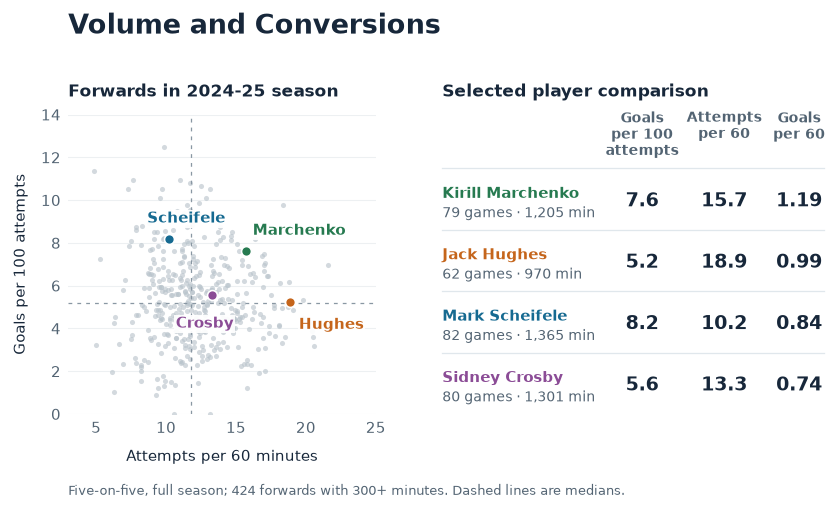

In [3]:
COLORS = {"Mark Scheifele":"#166A91", "Jack Hughes":"#C5651B", "Sidney Crosby":"#8B4C96", "Kirill Marchenko":"#267A50"}
OFFSETS = {"Mark Scheifele":(-12,9), "Jack Hughes":(5,-15), "Sidney Crosby":(-20,-18), "Kirill Marchenko":(4,9)}
base, profiles = nhl_volume_population, nhl_volume_profiles
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 8.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "svg.fonttype": "none",
})
dark, muted = "#17273A", "#536473"
fig = plt.figure(figsize=(6.5, 4.15), facecolor="white")
gs = fig.add_gridspec(1, 2, left=.095, right=.960, bottom=.235, top=.79,
                      width_ratios=[1, 1.16], wspace=.20)
ax, table = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
fig.text(.095, .94, "Volume and Conversions", fontsize=15, fontweight="bold", color=dark)
ax.set_title("Forwards in 2024-25 season", loc="left", fontsize=9.3,
             fontweight="bold", pad=10, color=dark)
table.set_title("Selected player comparison", loc="left", fontsize=9.3,
                fontweight="bold", pad=10, color=dark)
ax.scatter(base.A60, base.G100, s=8, color="#B8C3CB", alpha=.62, linewidths=0)
ax.axvline(base.A60.median(), color="#8997A3", ls=(0, (3, 4)), lw=.7)
ax.axhline(base.G100.median(), color="#8997A3", ls=(0, (3, 4)), lw=.7)
for p in profiles.itertuples():
    color = COLORS[p.name]
    ax.scatter(p.A60, p.G100, s=30, color=color, edgecolors="white", linewidths=.9, zorder=5)
    ax.annotate(p.name.split()[-1], (p.A60, p.G100), xytext=OFFSETS[p.name],
                textcoords="offset points", color=color, fontsize=8.5,
                fontweight="bold", zorder=6,
                bbox={"facecolor": "white", "alpha": .93, "edgecolor": "none", "pad": .8})
ax.set_xlabel("Attempts per 60 minutes", labelpad=7, color=dark, fontsize=8.5)
ax.set_ylabel("Goals per 100 attempts", labelpad=7, color=dark, fontsize=8.5)
ax.set_xlim(3, 25)
ax.set_ylim(0, 14)
ax.set_xticks([5, 10, 15, 20, 25])
ax.set_yticks(range(0, 15, 2))
ax.set_axisbelow(True)
ax.grid(axis="y", color="#EDF0F2", linewidth=.6)
ax.tick_params(axis="both", colors=muted, length=0, pad=4)

table.set_axis_off()
columns = [(0.56, "Goals\nper 100\nattempts", "G100", 1),
           (.79, "Attempts\nper 60", "A60", 1),
           (1.0, "Goals\nper 60", "G60", 2)]
for x, label, _, _ in columns:
    table.text(x, 1.015, label, transform=table.transAxes, ha="center", va="top",
               fontsize=7.5, fontweight="bold", color=muted)
for i, p in enumerate(profiles.itertuples()):
    y = .705 - i * .205
    table.plot([0, 1.07], [y+.115, y+.115], transform=table.transAxes,
               color="#E0E7EC", linewidth=.7, clip_on=False)
    table.text(0, y+.03, p.name, transform=table.transAxes, color=COLORS[p.name],
               fontweight="bold", fontsize=8.5, va="center")
    table.text(0, y-.035, f"{int(p.games)} games · {p.minutes:,.0f} min",
               transform=table.transAxes, fontsize=7.5, color=muted, va="center")
    for x, _, metric, digits in columns:
        table.text(x, y+.005, f"{getattr(p, metric):.{digits}f}", transform=table.transAxes,
                   fontsize=10.5, color=dark, ha="center", va="center", fontweight="bold")

fig.text(.095, .085,
         "Five-on-five, full season; 424 forwards with 300+ minutes. Dashed lines are medians.",
         fontsize=7.2, color=muted)

fig.savefig(OUTPUT / "volume_and_conversions.png", dpi=450, facecolor="white")
plt.show()


### Incremental predictive value

The target is next-season actual goals per 60. Controls are position, age, squared distance of age from 27, prior minutes per game, and offensive-zone start share. Ridge regressions use minutes as weights and select the penalty by chronological validation within 2021–22 through 2024–25. All models then forecast 2025–26 using the same players and outcome weights. The document's 12.1% and 2.9% are reductions in **weighted mean squared error**, relative to the corresponding one-history model.


In [4]:
nhl_seasons = pd.read_csv(NHL_INPUT / "nhl_seasons.csv", dtype={"player_id":str})
nhl_births = (pd.read_csv(NHL_INPUT / "nhl_birth_dates.csv", dtype={"player_id":str})
              .drop_duplicates("player_id").set_index("player_id").birthDate)
nhl_history = nhl_seasons.loc[nhl_seasons.season.le(2024)]
nhl_feature_rows = []
for target_season in range(2021, 2026):
    one = nhl_history.loc[nhl_history.season.eq(target_season-1)]
    one = one.loc[one.minutes.ge(100) & one.attempts.gt(0)]
    three = (nhl_history.loc[nhl_history.season.between(target_season-3, target_season-1)]
             .groupby("player_id")[["minutes","attempts","goals"]].sum())
    for r in one.itertuples():
        birth = pd.to_datetime(nhl_births.get(r.player_id, None))
        age = (pd.Timestamp(f"{target_season}-09-15")-birth).days/365.25 if pd.notna(birth) else np.nan
        row = dict(player_id=r.player_id, season=target_season, defense=float(r.position=="D"),
                   age=age, age_squared=(age-27)**2, minutes_per_game=r.minutes/r.games,
                   oz_share=r.oz_starts/(r.oz_starts+r.dz_starts) if r.oz_starts+r.dz_starts>0 else np.nan)
        for suffix, record in [("1",r),("3",three.loc[r.player_id])]:
            row["conversion"+suffix] = record.goals/record.attempts
            row["attempts60_"+suffix] = 60*record.attempts/record.minutes
        nhl_feature_rows.append(row)
nhl_features = pd.DataFrame(nhl_feature_rows)
nhl_targets = nhl_seasons[["season","player_id","minutes","goals"]].rename(columns={"minutes":"target_minutes","goals":"target_goals"})
nhl_regression = nhl_features.merge(nhl_targets, on=["season","player_id"], how="left", validate="1:1")
nhl_regression = nhl_regression.loc[nhl_regression.target_minutes.gt(0)].copy()
nhl_regression["goals60"] = 60*nhl_regression.target_goals/nhl_regression.target_minutes
nhl_development = nhl_regression.loc[nhl_regression.season.le(2024)]
nhl_validation = nhl_regression.loc[nhl_regression.season.eq(2025)]

def nhl_design(frame, model):
    shooting = []
    if model in ["conversion", "combined"]:
        shooting += ["conversion1", "conversion3"]
    if model in ["attempts", "combined"]:
        shooting += ["attempts60_1", "attempts60_3"]
    x = frame[["defense","age","age_squared","minutes_per_game","oz_share"]+shooting].copy()
    for column in shooting:
        x[column+"_D"] = x[column]*frame.defense
    return x


In [5]:
def nhl_ridge_fit(x, y, w, alpha):
    columns = list(x.columns)
    a = x.to_numpy(float)
    med = np.nanmedian(a, axis=0)
    assert np.isfinite(med).all()
    a = np.where(np.isfinite(a), a, med)
    w = np.asarray(w, float); w = w/w.sum()
    mean = np.sum(w[:, None]*a, axis=0)
    scale = np.sqrt(np.sum(w[:, None]*(a-mean)**2, axis=0))
    scale = np.where(scale > 1e-10, scale, 1)
    z = np.column_stack([np.ones(len(a)), (a-mean)/scale])
    zw = z*np.sqrt(w[:, None]); yw = np.asarray(y)*np.sqrt(w)
    if alpha:
        penalty = np.eye(z.shape[1])*np.sqrt(alpha); penalty[0, 0] = 0
        zw = np.vstack([zw, penalty]); yw = np.r_[yw, np.zeros(z.shape[1])]
    beta = np.linalg.lstsq(zw, yw, rcond=None)[0]
    return dict(columns=columns, median=med.tolist(), mean=mean.tolist(), scale=scale.tolist(), beta=beta.tolist(), alpha=alpha)

def nhl_ridge_predict(fitted, x):
    a = x[fitted['columns']].to_numpy(float)
    a = np.where(np.isfinite(a), a, np.array(fitted['median']))
    z = np.column_stack([np.ones(len(a)), (a-np.array(fitted['mean']))/np.array(fitted['scale'])])
    return np.maximum(z@np.array(fitted['beta']), 0)


In [6]:
nhl_ridge_models, nhl_mse = {}, {}
for model in ["conversion", "attempts", "combined"]:
    penalty_losses = {}
    for penalty in [0., .001, .01, .1, 1.]:
        weighted_sse, total_minutes = 0., 0.
        for year in [2022, 2023, 2024]:
            train = nhl_development.loc[nhl_development.season.lt(year)]
            valid = nhl_development.loc[nhl_development.season.eq(year)]
            fit = nhl_ridge_fit(nhl_design(train,model),train.goals60,train.target_minutes,penalty)
            prediction = nhl_ridge_predict(fit,nhl_design(valid,model))
            weighted_sse += np.sum(valid.target_minutes*(prediction-valid.goals60)**2)
            total_minutes += valid.target_minutes.sum()
        penalty_losses[penalty] = weighted_sse/total_minutes
    penalty = min(penalty_losses,key=lambda a:(round(penalty_losses[a],14),-a))
    fit = nhl_ridge_fit(nhl_design(nhl_development,model),nhl_development.goals60,nhl_development.target_minutes,penalty)
    nhl_ridge_models[model] = fit
    prediction = nhl_ridge_predict(fit,nhl_design(nhl_validation,model))
    nhl_mse[model] = np.average((prediction-nhl_validation.goals60)**2,weights=nhl_validation.target_minutes)
nhl_incremental = pd.DataFrame({
    "Addition to model":["Add attempt-rate history to conversion history", "Add conversion history to attempt-rate history"],
    "MSE reduction (%)":[100*(1-nhl_mse["combined"]/nhl_mse["conversion"]),100*(1-nhl_mse["combined"]/nhl_mse["attempts"])]})
nhl_incremental.to_csv(OUTPUT / "incremental_prediction.csv",index=False)
display(nhl_incremental.style.format({"MSE reduction (%)":"{:.1f}"}).hide(axis="index"))


Addition to model,MSE reduction (%)
Add attempt-rate history to conversion history,12.1
Add conversion history to attempt-rate history,2.9


## Data cleaning

Retain `location_on_net` in the cleaned data for the conditional on-net model.
Each model selects its own predictors: the one-stage models exclude this field.
Keep missing coordinates in the population; the coordinate-dependent model estimates
inverse-probability weights from its training data.

In [7]:
X = 'lateral_location_on_net'
Y = 'vertical_location_on_net'
raw_source = pd.read_csv(
    PROJECT / 'data/raw/shot-data.csv',
    keep_default_na=False, na_values=['', 'NA'],
)
source_columns = list(raw_source.columns)
duplicate_excess = raw_source.duplicated(source_columns, keep='first')
shots = raw_source.loc[~duplicate_excess].copy()
shots.insert(0, 'csv_line', shots.index.to_numpy() + 2)
shots['season'] = shots.season.astype(int)
shots['is_goal'] = shots.is_goal.astype('int8')

shots['outcome_inferred_from_goal'] = shots.outcome.isna() & shots.is_goal.eq(1)
shots['outcome_clean'] = shots.outcome.astype('string')
shots.loc[shots.outcome_inferred_from_goal, 'outcome_clean'] = 'onnet'
shots['coordinate_pair_observed'] = shots[[X, Y]].notna().all(axis=1)
shots['coordinate_pair_missing'] = shots[[X, Y]].isna().all(axis=1)

low_band = shots[Y].between(0, 0.5, inclusive='both')
shots['height_low_band'] = low_band.astype('boolean').mask(shots[Y].isna())
shots['height_outside_low_band_ft'] = shots[Y].mask(low_band, 0.0)
shots['negative_height'] = shots[Y].lt(0)
shots['extreme_goal_projection'] = (
    shots.is_goal.eq(1) & shots.coordinate_pair_observed
    & (shots[X].abs().gt(6) | shots[Y].gt(6))
)
analysis_populations = {
    'including_extreme_goals': shots.copy(),
    'excluding_extreme_goals': shots.loc[~shots.extreme_goal_projection].copy(),
}
shots.to_csv(OUTPUT / 'shots_cleaned.csv', index=False)

In [8]:
cleaning_table = pd.DataFrame([
    ('Exact copies', int(duplicate_excess.sum()), 'Keep the first copy'),
    ('Missing outcomes', int(shots.outcome_inferred_from_goal.sum()),
     'Fill derived outcome as onnet for recorded goals'),
    ('Missing coordinate pairs', int(shots.coordinate_pair_missing.sum()),
     'Retain; use IPW in coordinate-dependent fitting'),
    ('Goals with missing coordinates',
     int(shots.loc[shots.coordinate_pair_missing, 'is_goal'].sum()), 'Retain'),
    ('Heights from 0 through 0.5 ft', int(low_band.sum()), 'Use one height band'),
    ('Negative heights', int(shots.negative_height.sum()), 'Retain'),
    ('Extreme-projection goals', int(shots.extreme_goal_projection.sum()),
     'Compare the same models including and excluding these goals'),
    ('Blocks without location_on_net',
     int((shots.outcome_clean.eq('blocked') & shots.location_on_net.isna()).sum()),
     'Use location_on_net only in conditional on-net modeling'),
], columns=['Issue', 'Count', 'Treatment'])
display(cleaning_table)
population_counts = pd.DataFrame({name: {
    'Attempts': len(frame), 'Goals': int(frame.is_goal.sum()),
    'Players': frame.shooter_id.nunique(),
} for name, frame in analysis_populations.items()}).T
display(population_counts)
cleaning_table.to_csv(OUTPUT / 'cleaning_table.csv', index=False)
population_counts.to_csv(OUTPUT / 'population_counts.csv')

,Issue,Count,Treatment
0,Exact copies,45,Keep the first copy
1,Missing outcomes,48,Fill derived outcome as onnet for recorded goals
2,Missing coordinate pairs,1142,Retain; use IPW in coordinate-dependent fitting
3,Goals with missing coordinates,42,Retain
4,Heights from 0 through 0.5 ft,4950,Use one height band
5,Negative heights,17,Retain
6,Extreme-projection goals,68,Compare the same models including and excludin...
7,Blocks without location_on_net,2531,Use location_on_net only in conditional on-net...


,Attempts,Goals,Players
including_extreme_goals,13224,997,35
excluding_extreme_goals,13156,929,35


## NHL partial pooling

Following the predictive rationale in [Brown (2008), *In-season prediction of batting averages*](https://arxiv.org/abs/0803.3697), compare each player's raw conversion rate with one shared rate and a hierarchical binomial model:

\[
G_i\sim\mathrm{Binomial}(N_i,p_i),\quad
\mathrm{logit}(p_i)=\alpha+u_i,\quad
u_i\sim N(0,\tau^2),\quad
\alpha\sim N(\mathrm{logit}(0.06),2.5^2),\quad \tau\sim\mathrm{HalfNormal}(0.5).
\]

These NHL counts include every situation and blocked attempts. One fit uses 2024–25; the other combines 2021–22 through 2024–25. Each learns a single baseline and population dispersion from training counts. The rate RMSE table evaluates 2025–26 returners with 61–1,033 earlier attempts, with equal weight per player. The grouped chart uses all earlier attempt counts and fixed training-rate quintiles.


In [9]:
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, init_to_median

nhl_halves = pd.read_csv(NHL_INPUT / "nhl_all_situations_halves.csv")

def nhl_aggregate_counts(frame):
    totals = frame.groupby("player_id")[["goals","attempts","games"]].sum()
    latest = frame.sort_values(["season","half"]).groupby("player_id").tail(1).set_index("player_id")
    result = totals.join(latest[["name","position"]])
    return result.loc[result.attempts.gt(0)].sort_index().reset_index()

def nhl_count_model(player_index, season_index, attempts, goals, nplayers, nseasons):
    alpha = numpyro.sample("alpha",dist.Normal(float(logit(.06)),2.5).expand([nseasons]).to_event(1))
    tau = numpyro.sample("tau",dist.HalfNormal(.5))
    z = numpyro.sample("z",dist.Normal(0,1).expand([nplayers]).to_event(1))
    u = numpyro.deterministic("u",tau*z)
    logits = alpha[season_index]+u[player_index]
    numpyro.sample("goals",dist.Binomial(total_count=attempts,logits=logits).to_event(1),obs=goals)

def fit_nhl_counts(counts, seed):
    frame = counts.sort_values("player_id").reset_index(drop=True)
    kernel = NUTS(nhl_count_model,target_accept_prob=.97,max_tree_depth=10,
                  init_strategy=init_to_median(num_samples=25))
    sampler = MCMC(kernel,num_warmup=1000,num_samples=1500,num_chains=4,
                   chain_method="vectorized",progress_bar=False)
    sampler.run(jax.random.key(seed),jnp.arange(len(frame)),jnp.zeros(len(frame),dtype=int),
                jnp.asarray(frame.attempts.to_numpy()),jnp.asarray(frame.goals.to_numpy()),len(frame),1)
    draws = {key:np.asarray(value) for key,value in sampler.get_samples().items()}
    return {**draws,"player_ids":frame.player_id.to_numpy()}

nhl_training = nhl_halves.loc[nhl_halves.season.le(2024)]
nhl_future = nhl_aggregate_counts(nhl_halves.loc[nhl_halves.season.eq(2025)])
nhl_future = nhl_future[["player_id","goals","attempts"]].rename(columns={"goals":"future_goals","attempts":"future_attempts"})
nhl_fits, nhl_forecasts, nhl_forecast_errors = {}, {}, []
for label, lower, seed in [("One earlier season",2024,20261003),("Four earlier seasons",2021,20261007)]:
    counts = nhl_aggregate_counts(nhl_training.loc[nhl_training.season.ge(lower)])
    counts = counts.loc[counts.position.isin(["C","L","R"])].copy()
    fit = fit_nhl_counts(counts,seed)
    nhl_fits[label] = fit
    forecast = counts.set_index("player_id").loc[fit["player_ids"]].reset_index()
    forecast["raw"] = forecast.goals/forecast.attempts
    forecast["pooled"] = expit(fit["alpha"]+fit["u"]).mean(axis=0)
    forecast["shared"] = forecast.goals.sum()/forecast.attempts.sum()
    nhl_forecasts[label] = forecast
    evaluation = forecast.merge(nhl_future,on="player_id",how="inner",validate="1:1")
    evaluation = evaluation.loc[evaluation.attempts.between(61,1033)]
    observed = evaluation.future_goals/evaluation.future_attempts
    for method, title in [("raw","Raw rates"),("shared","One shared rate"),("pooled","Partial pooling")]:
        nhl_forecast_errors.append({"Forecast method":title,"History":label,
                                    "RMSE":100*np.sqrt(np.mean((evaluation[method]-observed)**2))})
nhl_rmse_table = (pd.DataFrame(nhl_forecast_errors).pivot(index="Forecast method",columns="History",values="RMSE")
                  .reindex(index=["Raw rates","One shared rate","Partial pooling"],columns=["One earlier season","Four earlier seasons"]))
nhl_rmse_table.to_csv(OUTPUT / "nhl_conversion_forecast_rmse.csv")
display(nhl_rmse_table.style.format("{:.2f}"))


History,One earlier season,Four earlier seasons
Forecast method,,
Raw rates,3.21,3.64
One shared rate,2.92,3.66
Partial pooling,2.82,3.46


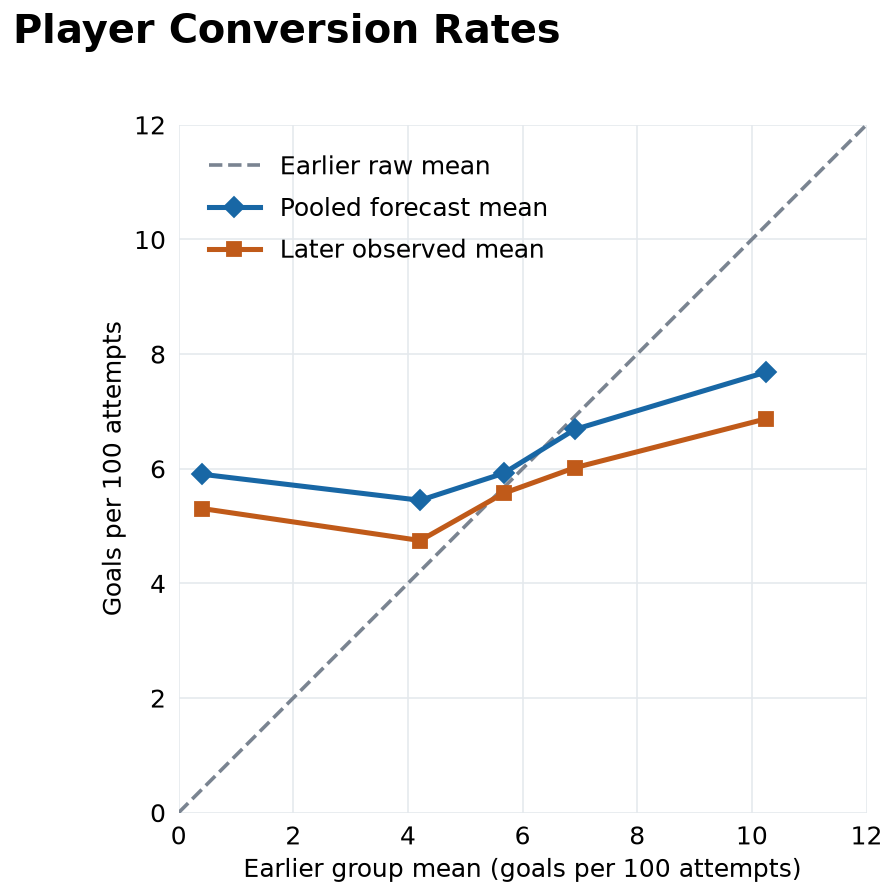

In [10]:
nhl_four_year = nhl_forecasts["Four earlier seasons"].copy()
nhl_four_year["group"] = pd.qcut(nhl_four_year.raw,5,labels=False,duplicates="drop")
nhl_grouped = nhl_four_year.merge(nhl_future,on="player_id",how="inner",validate="1:1")
nhl_grouped["later"] = nhl_grouped.future_goals/nhl_grouped.future_attempts
nhl_group_means = 100*nhl_grouped.groupby("group")[["raw","pooled","later"]].mean()
nhl_group_means.to_csv(OUTPUT / "player_conversion_group_means.csv")
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":14,"axes.spines.top":False,
                     "axes.spines.right":False,"axes.spines.left":False})
fig, ax = plt.subplots(figsize=(8,7.4))
fig.subplots_adjust(left=.135,right=.965,bottom=.145,top=.86)
fig.text(.06,.945,"Player Conversion Rates",fontsize=22,weight="bold")
ax.plot([0,12],[0,12],color="#7a8491",ls="--",lw=2,label="Earlier raw mean")
ax.plot(nhl_group_means.raw,nhl_group_means.pooled,color="#1867a5",marker="D",ms=8,lw=2.8,label="Pooled forecast mean")
ax.plot(nhl_group_means.raw,nhl_group_means.later,color="#c05a19",marker="s",ms=8,lw=2.8,label="Later observed mean")
ax.set(xlabel="Earlier group mean (goals per 100 attempts)",ylabel="Goals per 100 attempts",xlim=(0,12),ylim=(0,12),
       xticks=np.arange(0,13,2),yticks=np.arange(0,13,2))
ax.tick_params(length=0,pad=7)
ax.grid(color="#e5e9ed",linewidth=.9); ax.set_axisbelow(True)
ax.set_aspect("equal",adjustable="box")
ax.legend(loc="upper left",frameon=False,fontsize=14,labelspacing=.65,borderaxespad=.8)
fig.savefig(OUTPUT / "player_conversion_rates.png",dpi=330,facecolor="white")
plt.show()


## Conversion rate models

Forecasts use previous seasons to estimate each player's next-season goals per attempt. Development consists of 2021→2022 and 2021–2022→2023; we average the two player-level MSEs equally before taking the square root. Validation trains through 2023 and forecasts 2024. Every player has equal scoring weight, including players with few future attempts. The table's unit is percentage points.

The direct binomial and four-outcome softmax models learn persistent player effects and season intercepts jointly. Partial pooling enters their likelihoods through normally distributed **log-odds** effects. Their scale has a HalfNormal(0.5) prior. The direct season intercept prior is Normal(logit(0.06), 2.5²); the softmax has independent Normal(0, 2.5²) season logits, with on-net non-goals as the reference outcome. Forecasts carry forward the latest training-season baseline.

The two-stage forecast combines an on-net model, conditional scoring given on-net placement, and a training-only future placement distribution. Manual `location_on_net` stays available for this conditional model. Original goal/outcome counts identify the one-stage models, so those models include coordinate-missing attempts without IPW. IPW applies to the two-stage model's coordinate-observed history.


In [11]:
from dataclasses import dataclass, field
from typing import Any
from scipy.special import expit, logit, softmax, logsumexp, gammaln
from scipy.stats import rankdata, norm
from scipy.optimize import minimize, minimize_scalar
from numpy.polynomial.hermite import hermgauss
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from threadpoolctl import threadpool_limits
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, init_to_median

# Keep deterministic CPU calculations compact and avoid excess BLAS threads.
private_thread_limit = threadpool_limits(limits=1)
PRIVATE_CLASSES = ['goal', 'onnet_non_goal', 'missed', 'blocked']
ALPHA_MEAN, ALPHA_SD = float(logit(.06)), 2.5
private_data = shots.copy()
private_data['onnet'] = private_data.is_goal.eq(1) | private_data.outcome_clean.eq('onnet')
private_data['class_index'] = np.select(
    [private_data.is_goal.eq(1), private_data.onnet, private_data.outcome_clean.eq('missed')],
    [0, 1, 2], default=3)
assert len(private_data) == 13224 and private_data.is_goal.sum() == 997
assert private_data.loc[private_data.onnet, 'location_on_net'].notna().all()


In [12]:
def private_binomial_model(player_index, season_index, attempts, goals, nplayers, nseasons,
           tau_scale=.5, fixed_tau=None):
    import jax.numpy as jnp
    import numpyro
    import numpyro.distributions as dist
    alpha = numpyro.sample("alpha", dist.Normal(ALPHA_MEAN, ALPHA_SD).expand([nseasons]).to_event(1))
    if fixed_tau is None:
        tau = numpyro.sample("tau", dist.HalfNormal(tau_scale))
    else:
        tau = numpyro.deterministic("tau", jnp.asarray(fixed_tau))
    if fixed_tau == 0:
        u = numpyro.deterministic("u", jnp.zeros(nplayers))
    else:
        z = numpyro.sample("z", dist.Normal(0,1).expand([nplayers]).to_event(1))
        u = numpyro.deterministic("u", tau*z)
    logits = alpha[season_index]+u[player_index]
    numpyro.sample("goals", dist.Binomial(total_count=attempts, logits=logits).to_event(1), obs=goals)

def _split_chains(values):
    half = values.shape[1]//2
    return np.concatenate([values[:, :half], values[:, -half:]], axis=0)

def _rank_normalize(values):
    flat = values.reshape(-1, values.shape[-1])
    ranks = rankdata(flat, axis=0, method="average")
    normalized = norm.ppf((ranks-.375)/(len(flat)+.25))
    return normalized.reshape(values.shape)

def _parameter_diagnostics(chain_samples):
    """Rank-normalized split/folded R-hat, bulk ESS and tail ESS."""
    from numpyro.diagnostics import effective_sample_size, gelman_rubin
    rows = []
    for name in ("alpha", "tau", "u"):
        original = np.asarray(chain_samples[name])
        x = original.reshape(original.shape[0], original.shape[1], -1)
        varying = np.ptp(x, axis=(0,1)) > 0
        if not varying.any():
            continue
        active = x[:, :, varying]
        split = _split_chains(active)
        ranked = _rank_normalize(split)
        folded = _rank_normalize(np.abs(split-np.median(split, axis=(0,1))))
        rhat = np.maximum(np.asarray(gelman_rubin(ranked)), np.asarray(gelman_rubin(folded)))
        bulk = np.asarray(effective_sample_size(ranked))
        q05, q95 = np.quantile(active,[.05,.95],axis=(0,1))
        tail = np.minimum(np.asarray(effective_sample_size((split<=q05).astype(float))), np.asarray(effective_sample_size((split>=q95).astype(float))))
        means, sds = active.mean(axis=(0,1)), active.std(axis=(0,1),ddof=1)
        for local, index in enumerate(np.flatnonzero(varying)):
            rows.append(dict(parameter=f"{name}[{index}]" if name!="tau" else name, mean=float(means[local]),sd=float(sds[local]),rank_split_rhat=float(rhat[local]),bulk_ess=float(bulk[local]),tail_ess=float(tail[local]),mean_mcse_approx=float(sds[local]/np.sqrt(bulk[local]))))
    return pd.DataFrame(rows)

def private_softmax_model(pindex,sindex,attempts,counts,nplayers,nseasons,tau_scale=.5):
    import jax.numpy as jnp
    import numpyro
    import numpyro.distributions as dist
    alpha=numpyro.sample('alpha',dist.Normal(0,ALPHA_SD).expand([nseasons,3]).to_event(2))
    tau=numpyro.sample('tau',dist.HalfNormal(tau_scale).expand([3]).to_event(1))
    z=numpyro.sample('z',dist.Normal(0,1).expand([nplayers,3]).to_event(2))
    u=numpyro.deterministic('u',z*tau)
    active=alpha[sindex]+u[pindex]
    logits=jnp.stack((active[:,0],jnp.zeros_like(active[:,0]),active[:,1],active[:,2]),axis=-1)
    numpyro.sample('class_counts',dist.Multinomial(total_count=attempts,logits=logits).to_event(1),obs=counts)

def private_count_table(frame, multinomial=False, collapse_years=False):
    if multinomial:
        counts = (frame.groupby(['shooter_id', 'season', 'class_index']).size()
                  .unstack(fill_value=0).reindex(columns=range(4), fill_value=0)
                  .reset_index().rename(columns={'shooter_id':'player_id'}))
        counts = counts.rename(columns=dict(enumerate(PRIVATE_CLASSES)))
        counts['attempts'] = counts[PRIVATE_CLASSES].sum(axis=1)
    else:
        group = ['shooter_id'] if collapse_years else ['shooter_id', 'season']
        counts = (frame.groupby(group).agg(goals=('is_goal','sum'), attempts=('is_goal','size'))
                  .reset_index().rename(columns={'shooter_id':'player_id'}))
        if collapse_years:
            counts['season'] = 'all_years'
    for name in ['attempts'] + (PRIVATE_CLASSES if multinomial else ['goals']):
        counts[name] = counts[name].astype('int64')
    return counts.sort_values(['player_id','season']).reset_index(drop=True)

def private_bayes_fit(counts, seed, multinomial=False, warmup=1500, samples=2000, target=.97):
    players, seasons = np.sort(counts.player_id.unique()), np.sort(counts.season.unique())
    pmap, smap = ({v:i for i,v in enumerate(a)} for a in (players, seasons))
    kernel = NUTS(private_softmax_model if multinomial else private_binomial_model,
                  target_accept_prob=target, max_tree_depth=10,
                  init_strategy=init_to_median(num_samples=25))
    sampler = MCMC(kernel, num_warmup=warmup, num_samples=samples,
                   num_chains=4, chain_method='vectorized', progress_bar=False)
    observed = counts[PRIVATE_CLASSES].to_numpy() if multinomial else counts.goals.to_numpy()
    options = {'tau_scale':.5} if multinomial else {'tau_scale':.5, 'fixed_tau':None}
    extras = ('diverging','accept_prob','num_steps','energy') if multinomial else (
        'diverging','accept_prob','num_steps','energy','potential_energy')
    sampler.run(jax.random.key(seed), jnp.asarray(counts.player_id.map(pmap).to_numpy()),
                jnp.asarray(counts.season.map(smap).to_numpy()),
                jnp.asarray(counts.attempts.to_numpy()), jnp.asarray(observed),
                len(players), len(seasons), **options, extra_fields=extras)
    draws = {k:np.asarray(v) for k,v in sampler.get_samples(group_by_chain=True).items()}
    extra = {k:np.asarray(v) for k,v in sampler.get_extra_fields(group_by_chain=True).items()}
    diagnostic = _parameter_diagnostics(draws)
    bfmi = np.mean(np.diff(extra['energy'],axis=1)**2,axis=1)/np.var(extra['energy'],axis=1)
    assert (extra['diverging'].sum() == 0 and diagnostic.rank_split_rhat.max() < 1.01
            and diagnostic.bulk_ess.min() >= 400 and diagnostic.tail_ess.min() >= 400
            and bfmi.min() > .3 and not (extra['num_steps'] >= 2**10-1).any())
    return {**{k:v.reshape((-1,)+v.shape[2:]) for k,v in draws.items() if k in ['alpha','u','tau']},
            'player_ids':players, 'seasons':seasons}

def private_latest_probability(fitted, multinomial=False):
    eta = fitted['alpha'][:, -1, ...][:, None, ...] + fitted['u']
    if multinomial:
        logits = np.zeros(eta.shape[:-1]+(4,))
        logits[..., [0,2,3]] = eta
        return softmax(logits, axis=-1)[...,0].mean(axis=0)
    return expit(eta).mean(axis=0)


### Conditional placement and missing coordinates

Fit coordinate-observation probabilities using shooter, season, retrospective outcome class, and manual region. Five-fold cross-fitting supplies each historical row's observation probability. This assumes the missing coordinate mechanism is represented by those observed fields. The conditional scoring fit uses inverse probabilities normalized to mean one. The spline basis retains lateral location, the 0–0.5 ft low-height band, and height outside that band, alongside manual region.

Choose the conditional surface penalty from {0.1, 1, 10} by the mean IPW conditional goal log loss in the two development seasons. Freeze it before 2024. Player random effects use empirical-Bayes integrated logistic likelihood. The code below integrates each player's conditional effect distribution rather than treating its fitted mean as certain.


In [13]:
@dataclass
class LogisticFit:
    pooling: str
    beta: np.ndarray
    player_ids: np.ndarray
    player_effects: np.ndarray
    tau: float = 0.0
    posterior_nodes: np.ndarray = field(default_factory=lambda: np.empty((0, 0)))
    posterior_weights: np.ndarray = field(default_factory=lambda: np.empty((0, 0)))
    diagnostics: dict[str, Any] = field(default_factory=dict)

    def predict(self, X: np.ndarray, player: np.ndarray) -> np.ndarray:
        X = np.asarray(X, dtype=float)
        player = np.asarray(player)
        if X.ndim != 2 or X.shape[1] != len(self.beta):
            raise ValueError('Prediction X must match the fitted design columns.')
        if player.shape != (len(X),) or not np.isfinite(X).all():
            raise ValueError('Supply one player ID per finite design row.')
        offset = X @ self.beta
        if self.pooling == 'complete' or (self.pooling == 'partial' and self.tau == 0):
            return expit(offset)
        position = np.searchsorted(self.player_ids, player)
        safe = np.minimum(position, len(self.player_ids) - 1)
        known = (position < len(self.player_ids)) & (self.player_ids[safe] == player)
        result = np.empty(len(X))
        x, w = hermgauss(81)
        population_nodes, population_weights = (np.sqrt(2) * self.tau * x, w / np.sqrt(np.pi))
        for begin in range(0, len(X), 2048):
            end = min(begin + 2048, len(X))
            local_known = known[begin:end]
            values = np.empty(end - begin)
            if local_known.any():
                k = position[begin:end][local_known]
                values[local_known] = np.sum(expit(offset[begin:end][local_known, None] + self.posterior_nodes[k]) * self.posterior_weights[k], axis=1)
            if (~local_known).any():
                values[~local_known] = expit(offset[begin:end][~local_known, None] + population_nodes) @ population_weights
            result[begin:end] = values
        return result

def _projected_score(gradient, parameter, bounds):
    gradient = np.array(gradient, copy=True)
    for i, (lo, hi) in enumerate(bounds):
        if parameter[i] <= lo + 1e-07 and gradient[i] > 0:
            gradient[i] = 0.0
        if parameter[i] >= hi - 1e-07 and gradient[i] < 0:
            gradient[i] = 0.0
    return float(np.max(np.abs(gradient), initial=0.0))

def _minimize(objective, initial, bounds):
    return minimize(objective, initial, method='L-BFGS-B', jac=True, bounds=bounds, options={'maxiter': 2500, 'maxls': 50, 'maxcor': 25, 'ftol': 1e-14, 'gtol': 1e-07})

class _IntegratedLikelihood:

    def __init__(self, X, y, player, weights, penalty, order):
        sort = np.argsort(player, kind='stable')
        self.X, self.y = (X[sort], y[sort])
        self.player, self.weights = (player[sort], weights[sort])
        self.starts = np.flatnonzero(np.r_[True, np.diff(self.player) != 0])
        self.nplayers = len(self.starts)
        self.penalty = penalty
        self.order = order
        self.x, w = hermgauss(order)
        self.log_weights = np.log(w) - 0.5 * np.log(np.pi)

    def aggregate(self, array):
        return np.add.reduceat(array, self.starts, axis=0)

    def evaluate(self, parameter, full=False):
        beta, tau = (parameter[:-1], np.exp(parameter[-1]))
        offset = self.X @ beta
        inverse_variance = 1.0 / tau ** 2
        mode = np.zeros(self.nplayers)
        for _ in range(60):
            prob = expit(offset + mode[self.player])
            score = self.aggregate(self.weights * (self.y - prob)) - mode * inverse_variance
            curvature = self.aggregate(self.weights * prob * (1 - prob)) + inverse_variance
            step = np.clip(score / curvature, -5.0, 5.0)
            mode += step
            if np.max(np.abs(step)) < 1e-11:
                break
        prob = expit(offset + mode[self.player])
        scale = 1 / np.sqrt(self.aggregate(self.weights * prob * (1 - prob)) + inverse_variance)
        nodes = mode[:, None] + np.sqrt(2) * scale[:, None] * self.x
        eta = offset[:, None] + nodes[self.player]
        ll = self.aggregate(self.weights[:, None] * (self.y[:, None] * eta - np.logaddexp(0, eta)))
        log_mass = self.log_weights + ll - 0.5 * nodes ** 2 * inverse_variance + self.x ** 2
        normalizer = logsumexp(log_mass, axis=1)
        marginal = normalizer + np.log(scale / tau)
        post = np.exp(log_mass - normalizer[:, None])
        posterior_probability = np.sum(expit(eta) * post[self.player], axis=1)
        gradient_beta = self.X.T @ (self.weights * (self.y - posterior_probability))
        gradient_logtau = np.sum(post * nodes ** 2) * inverse_variance - self.nplayers
        objective = -marginal.sum() + 0.5 * np.dot(self.penalty, beta ** 2)
        gradient = np.r_[-gradient_beta + self.penalty * beta, -gradient_logtau]
        if full:
            return (float(objective), gradient, nodes, post, marginal, posterior_probability)
        return (float(objective), gradient)

def private_eb_fit(X, y, player, weights=None, spatial_penalty=1.0, penalty_mask=None, pooling='partial', seed=20260927) -> LogisticFit:
    X, y, supplied_player = (np.asarray(X, float), np.asarray(y, float), np.asarray(player))
    if pooling not in {'complete', 'partial'}:
        raise ValueError('Select complete, unpooled, or partial pooling.')
    if X.ndim != 2 or not len(X) or X.shape[1] < 1 or (y.shape != (len(X),)):
        raise ValueError('Supply a nonempty design and one binary response per row.')
    if not np.isfinite(X).all() or not np.allclose(X[:, 0], 1):
        raise ValueError('Use finite design values and an intercept in X[:, 0].')
    if not np.isin(y, [0, 1]).all():
        raise ValueError('Responses must be binary.')
    if supplied_player.shape != y.shape or not np.issubdtype(supplied_player.dtype, np.integer) or (supplied_player < 0).any():
        raise ValueError('Player IDs must be nonnegative integers, one per row.')
    if weights is None:
        weights = np.ones(len(X))
    weights = np.asarray(weights, float)
    if weights.shape != y.shape or not np.isfinite(weights).all() or (weights < 0).any() or (weights.sum() <= 0):
        raise ValueError('Use finite, nonnegative weights with positive total mass.')
    original_n = len(X)
    weight_scale = original_n / weights.sum()
    weights = weights * weight_scale
    positive = weights > 0
    X, y, supplied_player, weights = (X[positive], y[positive], supplied_player[positive], weights[positive])
    player_ids, player = np.unique(supplied_player, return_inverse=True)
    P, D = (len(player_ids), X.shape[1])
    if penalty_mask is None:
        penalty_mask = np.r_[False, np.ones(D - 1, dtype=bool)]
    mask = np.asarray(penalty_mask, bool)
    if mask.shape != (D,) or mask[0] or (not np.isfinite(spatial_penalty)) or (spatial_penalty < 0):
        raise ValueError('Use a nonnegative penalty and a mask excluding the intercept.')
    penalty = float(spatial_penalty) * mask
    bounds = [(-25.0, 25.0)] * D

    def complete_objective(beta):
        eta = X @ beta
        value = np.dot(weights, np.logaddexp(0, eta) - y * eta) + 0.5 * np.dot(penalty, beta ** 2)
        gradient = X.T @ (weights * (expit(eta) - y)) + penalty * beta
        return (float(value), gradient)
    initial = np.zeros(D)
    initial[0] = logit(np.clip(np.average(y, weights=weights), 1e-08, 1 - 1e-08))
    complete = _minimize(complete_objective, initial, bounds)
    complete_value, complete_gradient = complete_objective(complete.x)
    diagnostics = {'pooling': pooling, 'n_rows': int(original_n), 'positive_weight_rows': int(len(X)), 'n_players': int(P), 'n_columns': int(D), 'spatial_penalty': float(spatial_penalty), 'n_penalized_columns': int(mask.sum()), 'weight_normalization_multiplier': float(weight_scale), 'seed': int(seed), 'fixed_parameter_uncertainty_integrated': False, 'complete_penalized_nll': float(complete_value)}
    if pooling == 'complete':
        score = _projected_score(complete_gradient, complete.x, bounds)
        diagnostics.update({'optimizer_success': bool(complete.success), 'optimizer_message': str(complete.message), 'iterations': int(complete.nit), 'projected_score_max': score, 'score_check_pass': bool(score < 0.001), 'penalized_nll': float(complete_value), 'coefficient_boundary': bool((np.abs(complete.x) >= 24.999).any()), 'tau': 0.0, 'quadrature_check_pass': True})
        return LogisticFit(pooling, complete.x, player_ids, np.zeros(P), diagnostics=diagnostics)
    integrated = _IntegratedLikelihood(X, y, player, weights, penalty, order=21)
    partial_bounds = bounds + [(-8.0, 2.0)]
    runs = [_minimize(integrated.evaluate, np.r_[complete.x, np.log(tau)], partial_bounds) for tau in (0.15, 0.6)]
    result = min(runs, key=lambda run: run.fun)
    refinement_count = 0
    for order in (41, 81):
        fitted = integrated.evaluate(result.x, full=True)
        checked = _IntegratedLikelihood(X, y, player, weights, penalty, order=order)
        reference = checked.evaluate(result.x, full=True)
        likelihood_error = float(abs(reference[0] - fitted[0]))
        player_likelihood_error = float(np.max(np.abs(reference[4] - fitted[4])))
        probability_error = float(np.max(np.abs(reference[5] - fitted[5])))
        quadrature_pass = likelihood_error < 0.0001 and probability_error < 1e-06
        if quadrature_pass:
            break
        integrated = checked
        result = _minimize(integrated.evaluate, result.x, partial_bounds)
        refinement_count += 1
    else:
        fitted = integrated.evaluate(result.x, full=True)
        checked = _IntegratedLikelihood(X, y, player, weights, penalty, order=121)
        reference = checked.evaluate(result.x, full=True)
        likelihood_error = float(abs(reference[0] - fitted[0]))
        player_likelihood_error = float(np.max(np.abs(reference[4] - fitted[4])))
        probability_error = float(np.max(np.abs(reference[5] - fitted[5])))
        quadrature_pass = likelihood_error < 0.0001 and probability_error < 1e-06
    value, gradient, nodes, posterior_weights, _, _ = reference
    score = _projected_score(gradient, result.x, partial_bounds)
    boundary = complete_value <= value + 1e-07
    tau = 0.0 if boundary else float(np.exp(result.x[-1]))
    beta = complete.x if boundary else result.x[:-1]
    if boundary:
        nodes, posterior_weights = (np.zeros((P, 1)), np.ones((P, 1)))
        value, score = (complete_value, _projected_score(complete_gradient, complete.x, bounds))
    diagnostics.update({'optimizer_success': bool(complete.success if boundary else result.success), 'optimizer_message': str(complete.message if boundary else result.message), 'iterations': int(sum((run.nit for run in runs))), 'projected_score_max': score, 'score_check_pass': bool(score < 0.001), 'penalized_nll': float(value), 'coefficient_boundary': bool((np.abs(beta) >= 24.999).any()), 'tau': tau, 'tau_zero_boundary': bool(boundary), 'tau_upper_boundary': bool(not boundary and result.x[-1] >= 2 - 1e-06), 'quadrature_fit_order': int(integrated.order), 'quadrature_posterior_order': int(checked.order), 'quadrature_refinements': refinement_count, 'quadrature_check_pass': bool(quadrature_pass), 'quadrature_nll_absolute_difference': likelihood_error, 'quadrature_player_loglik_max_difference': player_likelihood_error, 'quadrature_prediction_max_difference': probability_error, 'multistart_objectives': [float(run.fun) for run in runs], 'estimation': 'Empirical Bayes: adaptive Gauss-Hermite integrated marginal likelihood, including the tau=0 boundary.'})
    return LogisticFit(pooling, beta, player_ids, (nodes * posterior_weights).sum(axis=1), tau=tau, posterior_nodes=nodes, posterior_weights=posterior_weights, diagnostics=diagnostics)


In [14]:
class ObservationModel:

    def covariates(self, d):
        season = d.season.clip(upper=self.latest).astype(str)
        return pd.DataFrame({'shooter': d.shooter_id.astype(str), 'season': season, 'outcome_class': d.class_index.astype(str)})

    def fit(self, d):
        self.latest = int(d.season.max())
        self.encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=True)
        X = self.encoder.fit_transform(self.covariates(d))
        self.model = LogisticRegression(C=1.0, solver='lbfgs', max_iter=1500, tol=1e-08)
        self.model.fit(X, d.coordinate_pair_observed.astype(int))
        if self.model.n_iter_.max() >= 1500:
            raise RuntimeError('Observation fit did not converge')
        return self

    def predict(self, d):
        return np.clip(self.model.predict_proba(self.encoder.transform(self.covariates(d)))[:, 1], 1e-06, 1 - 1e-06)

def feature_array(d):
    return np.column_stack([d.lateral_location_on_net.to_numpy(float), d.height_outside_low_band_ft.to_numpy(float), d.height_low_band.to_numpy(float)])

class Surface:

    def __init__(self, candidate, task):
        self.spec = candidate.copy()
        self.task = task
        self.k = 4 if task == 'all_multinomial' else 2

    def design(self, d, fit=False, weights=None):
        x = feature_array(d)
        assert np.isfinite(x).all()
        if self.spec['family'] != 'smooth':
            return x
        if fit:
            self.sx = SplineTransformer(knots=np.array([-6, -3, 0, 3, 6.0])[:, None], degree=3, include_bias=False, extrapolation='linear').fit(x[:, 0:1])
            self.sy = SplineTransformer(knots=np.array([-1, 0.5, 2, 4, 6.0])[:, None], degree=3, include_bias=False, extrapolation='linear').fit(x[:, 1:2])
        bx = self.sx.transform(x[:, 0:1])
        by = self.sy.transform(x[:, 1:2])
        low = x[:, 2:3]
        tensor = np.einsum('ni,nj->nij', bx, by).reshape(len(d), -1)
        raw = np.column_stack([bx, by, tensor, low, bx * low])
        if fit:
            self.scaler = StandardScaler().fit(raw, sample_weight=weights)
        return self.scaler.transform(raw)

class PlacementObservation(ObservationModel):
    def covariates(self,d):
        result=super().covariates(d)
        result['manual_region']=d.location_on_net.fillna('__missing__').astype(str)
        return result

class Design:
    def fit(self,frame,weights=None,locations=False):
        self.seasons=np.sort(frame.season.unique())
        self.locations=locations
        self.penalty_mask=np.zeros(len(self.seasons))
        if locations:
            self.surface=Surface({'family':'smooth','C':1.0},'onnet_binary')
            features=self.surface.design(frame,fit=True,weights=weights)
            self.region=OneHotEncoder(handle_unknown='ignore',drop='first',sparse_output=False)
            region=self.region.fit_transform(frame[['location_on_net']].fillna('__missing__'))
            self.penalty_mask=np.r_[self.penalty_mask,np.ones(features.shape[1]+region.shape[1])]
        return self
    def transform(self,frame):
        season=frame.season.clip(upper=self.seasons[-1]).to_numpy()
        x=np.column_stack([np.ones(len(frame)),(season[:,None]==self.seasons[1:]).astype(float)])
        if self.locations:
            x=np.column_stack([x,self.surface.design(frame),self.region.transform(frame[['location_on_net']].fillna('__missing__'))])
        return x

def private_observation_probabilities(train, test=None):
    observed = train.coordinate_pair_observed.astype(int).to_numpy()
    oof = np.zeros(len(train))
    folds = StratifiedKFold(5, shuffle=True, random_state=20260928)
    for it, iv in folds.split(train, observed):
        oof[iv] = PlacementObservation().fit(train.iloc[it]).predict(train.iloc[iv])
    future = PlacementObservation().fit(train).predict(test) if test is not None else None
    return oof, future

def private_conditional_fit(frame, response, weights, locations, penalty, pooling='partial'):
    design = Design().fit(frame, weights, locations)
    fitted = private_eb_fit(design.transform(frame), np.asarray(response,float),
                           frame.shooter_id.to_numpy(), weights=weights,
                           spatial_penalty=penalty, penalty_mask=design.penalty_mask,
                           pooling=pooling, seed=20260928)
    assert fitted.diagnostics['score_check_pass'] and fitted.diagnostics['quadrature_check_pass']
    return fitted, design

def private_logloss(y, p):
    p = np.clip(p, 1e-12, 1-1e-12)
    return -(y*np.log(p)+(1-y)*np.log1p(-p))

# Recompute nuisance tuning rather than substituting the saved selected value.
private_weight_cache, private_penalty_rows = {}, []
for through in [2021, 2022]:
    train = private_data[private_data.season.le(through)]
    test = private_data[private_data.season.eq(through+1)]
    pt, pe = private_observation_probabilities(train, test)
    private_weight_cache[('including',through)] = (pt,pe)
    mt, me = train.onnet & train.coordinate_pair_observed, test.onnet & test.coordinate_pair_observed
    for penalty in [.1, 1., 10.]:
        model, design = private_conditional_fit(train[mt], train.loc[mt,'is_goal'],
                                                1/pt[mt], True, penalty, 'complete')
        p = model.predict(design.transform(test[me]), test.loc[me,'shooter_id'].to_numpy())
        private_penalty_rows.append({'through':through, 'penalty':penalty,
            'conditional_logloss':np.average(private_logloss(test.loc[me,'is_goal'],p),weights=1/pe[me])})
private_penalty_scores = pd.DataFrame(private_penalty_rows)
private_penalty = float(private_penalty_scores.groupby('penalty').conditional_logloss.mean().idxmin())
private_penalty_scores.to_csv(OUTPUT/'conditional_penalty_selection.csv',index=False)
print('Frozen conditional placement penalty:', private_penalty)


Frozen conditional placement penalty: 0.1


Future placements are unknown when a forecast is issued. For each player, average conditional scoring over a mixture of their own historical on-net placements and the training population's placements. Both distributions use IPW. The player's mixture weight is n_eff/(n_eff + κ), where n_eff is the Kish effective sample size. Estimate κ from the training-only joint manual-region/lateral/height cells using a Dirichlet-multinomial fractional-count likelihood. The cells estimate the pooling strength; scoring still integrates the original continuous placement records.

This forecast uses each player's history throughout. Future outcomes and future coordinates enter evaluation and development tuning only.


In [15]:
MISSING_MANUAL = '<missing>'
LATERAL_LABELS = ('x < -3', '-3 <= x < 0', '0 <= x < 3', 'x >= 3')
HEIGHT_LABELS = ('negative', 'low band [0, 0.5]', '0.5 < h <= 2', '2 < h <= 4', 'h > 4')
REQUIRED_COLUMNS = ('shooter_id','location_on_net','lateral_location_on_net',
                    'height_outside_low_band_ft','height_low_band')
def _low_band_flag(values: pd.Series) -> np.ndarray:
    """Read the approved indicator, including its CSV string representation."""
    mapping = {True: True, False: False, "True": True, "False": False,
               "true": True, "false": False, 1: True, 0: False}
    mapped = values.map(mapping)
    if mapped.isna().any():
        raise ValueError("Supply a recorded Boolean height_low_band for every training row.")
    return mapped.to_numpy(dtype=bool)

def placement_cells(frame: pd.DataFrame) -> pd.DataFrame:
    """Prespecified coarse joint cells, retaining missing manual labels.

    Lateral cell endpoints are -3, 0, and 3 ft. The existing inclusive low
    height band remains one cell; other heights use negative, (0.5, 2],
    (2, 4], and (4, infinity). Only observed joint cells need prior mass.
    """
    missing = set(REQUIRED_COLUMNS) - set(frame.columns)
    if missing:
        raise ValueError(f"Supply placement columns: {sorted(missing)}")
    x = frame.lateral_location_on_net.to_numpy(dtype=float)
    h = frame.height_outside_low_band_ft.to_numpy(dtype=float)
    low = _low_band_flag(frame.height_low_band)
    if not np.isfinite(x).all() or not np.isfinite(h).all():
        raise ValueError("Supply coordinate-observed on-net training rows.")
    if ((~low) & (h >= 0) & (h <= 0.5)).any():
        raise ValueError("Use the approved inclusive low-height-band representation.")
    manual = frame.location_on_net.fillna(MISSING_MANUAL).astype(str)
    observed_reserved = frame.location_on_net.notna() & manual.eq(MISSING_MANUAL)
    if observed_reserved.any():
        raise ValueError(f"Manual category {MISSING_MANUAL!r} is reserved for missing values.")
    lateral = np.asarray(LATERAL_LABELS)[np.searchsorted([-3., 0., 3.], x, side="right")]
    height_index = np.select([low, h < 0, h <= 2, h <= 4], [1, 0, 2, 3], default=4)
    return pd.DataFrame({"location_on_net": manual.to_numpy(), "lateral_cell": lateral,
                         "height_cell": np.asarray(HEIGHT_LABELS)[height_index]}, index=frame.index)

def _log_marginal(kappa: float, counts: np.ndarray, base: np.ndarray) -> float:
    """Dirichlet pseudo marginal log likelihood, omitting count-only constants."""
    if np.isinf(kappa):
        return float(np.sum(counts * np.log(base)))
    if kappa == 0:
        occupied = counts > 0
        if np.any(occupied.sum(axis=1) > 1):
            return -np.inf
        return float(np.sum(np.log(base[np.argmax(occupied, axis=1)])))
    totals = counts.sum(axis=1)
    alpha = kappa * base
    return float(np.sum(gammaln(kappa) - gammaln(kappa + totals))
                 + np.sum(gammaln(alpha[None, :] + counts) - gammaln(alpha[None, :])))

def _estimate_concentration(counts, base, bounds):
    lo, hi = bounds
    if not (np.isfinite(lo) and np.isfinite(hi) and 0 < lo < hi):
        raise ValueError("Concentration bounds must be finite, positive, and increasing.")
    common_ll = _log_marginal(np.inf, counts, base)
    zero_ll = _log_marginal(0., counts, base)
    if len(base) == 1 or np.allclose(counts.sum(axis=1), 1., atol=1e-12, rtol=0):
        return np.inf, {"concentration_identified": False, "concentration_boundary": "common",
                        "pseudo_log_marginal": common_ll, "common_pseudo_log_marginal": common_ll,
                        "log_marginal_gain_over_common": 0., "optimizer_success": True}
    grid = np.linspace(np.log(lo), np.log(hi), 81)
    values = np.array([_log_marginal(np.exp(t), counts, base) for t in grid])
    candidates = [(float(np.exp(grid[k])), values[k]) for k in (0, len(grid)-1)]
    successes = []
    # Refine each grid-local optimum, including the best point's neighborhood.
    peaks = set((np.flatnonzero((values[1:-1] >= values[:-2]) &
                               (values[1:-1] >= values[2:])) + 1).tolist())
    peaks.add(int(np.argmax(values)))
    for k in sorted(peaks):
        left, right = grid[max(0, k-1)], grid[min(len(grid)-1, k+1)]
        result = minimize_scalar(lambda t: -_log_marginal(np.exp(t), counts, base),
                                 method="bounded", bounds=(left, right),
                                 options={"xatol": 1e-8})
        successes.append(bool(result.success))
        candidates.append((float(np.exp(result.x)), float(-result.fun)))
    kappa, best_ll = max(candidates, key=lambda candidate: candidate[1])
    boundary = "interior"
    # Exact limits keep numerically indistinguishable very strong pooling stable.
    if common_ll >= best_ll - 1e-6 and common_ll >= zero_ll - 1e-6:
        kappa, best_ll, boundary = np.inf, common_ll, "common"
    elif zero_ll >= best_ll - 1e-6:
        kappa, best_ll, boundary = 0., zero_ll, "unpooled"
    elif kappa <= lo * 1.001:
        boundary = "lower_search_bound"
    elif kappa >= hi / 1.001:
        boundary = "upper_search_bound"
    return kappa, {"concentration_identified": True, "concentration_boundary": boundary,
                   "pseudo_log_marginal": best_ll, "common_pseudo_log_marginal": common_ll,
                   "log_marginal_gain_over_common": best_ll-common_ll,
                   "optimizer_success": all(successes)}

def private_placement_weights(history, weights):
    cells = placement_cells(history)
    players, pi = np.unique(history.shooter_id.to_numpy(), return_inverse=True)
    ci, keys = pd.factorize(pd.MultiIndex.from_frame(cells), sort=True)
    totals = np.zeros((len(players),len(keys)))
    np.add.at(totals,(pi,ci),weights)
    mass = totals.sum(axis=1)
    ess = mass**2/np.bincount(pi,weights=weights**2,minlength=len(players))
    counts = totals*(ess/mass)[:,None]
    base = totals.sum(axis=0)/mass.sum()
    kappa, _ = _estimate_concentration(counts,base,(1e-6,1e5))
    return pd.Series(ess/(ess+kappa), index=players)

def private_two_stage(train, through, population):
    key = (population,through)
    if key not in private_weight_cache:
        private_weight_cache[key] = private_observation_probabilities(train)
    pt, _ = private_weight_cache[key]
    players = np.sort(train.shooter_id.unique())
    future = pd.DataFrame({'shooter_id':players,'season':through+1})
    onnet_fit,onnet_design = private_conditional_fit(
        train,train.onnet,np.ones(len(train)),False,private_penalty)
    p_onnet = onnet_fit.predict(onnet_design.transform(future),players)
    observed = train.onnet & train.coordinate_pair_observed
    history, weights = train.loc[observed].copy(), 1/pt[observed]
    fitted, design = private_conditional_fit(history,history.is_goal,weights,True,private_penalty)
    retained = private_placement_weights(history,weights).reindex(players,fill_value=0)
    reference = history.copy()
    reference['season'] = through
    X = design.transform(reference)
    conditional = []
    for player in players:
        p = fitted.predict(X,np.full(len(history),player))
        own = history.shooter_id.eq(player).to_numpy()
        common = np.average(p,weights=weights)
        individual = np.average(p[own],weights=weights[own]) if own.any() else common
        w = retained.loc[player]
        conditional.append(w*individual+(1-w)*common)
    return pd.DataFrame({'shooter_id':players,'p_goal':p_onnet*np.asarray(conditional)})


### Reproduce the model comparison

Fit each locked specification on the inclusive data and on the same data with flagged extreme-projection goals excluded. Evaluate both training policies on identical inclusive future attempts. This is the document's stated extreme-goal sensitivity; it changes the training population while holding the scoring population fixed. All reported models are fitted directly below.


In [16]:
private_forecasts = []
for population in ['including','excluding']:
    available = private_data if population == 'including' else private_data.loc[~private_data.extreme_goal_projection]
    for through in [2021,2022,2023]:
        train = available.loc[available.season.le(through)]
        for name, multinomial in [('Hierarchical',False),('Multinomial Logistic',True)]:
            if multinomial:
                seed = 20260927+through+50+(100 if population == 'excluding' else 0)
                fitted = private_bayes_fit(private_count_table(train,True),seed,True,
                                          warmup=1000,samples=1500,target=.95)
            else:
                seed = 20260928+1000*(population == 'excluding')+100*(through-2021)
                fitted = private_bayes_fit(private_count_table(train),seed)
            table = pd.DataFrame({'shooter_id':fitted['player_ids'],
                                  'p_goal':private_latest_probability(fitted,multinomial)})
            table = table.assign(model=name,population=population,season=through+1)
            private_forecasts.append(table)
        two = private_two_stage(train,through,population)
        private_forecasts.append(two.assign(model='Two stage',population=population,season=through+1))
        print('Completed',population,'training through',through)
private_forecasts = pd.concat(private_forecasts,ignore_index=True)
private_truth = (private_data.groupby(['shooter_id','season'])
                 .agg(goals=('is_goal','sum'),attempts=('is_goal','size')).reset_index())
private_evaluation = private_forecasts.merge(private_truth,on=['shooter_id','season'],validate='m:1')
private_evaluation['squared_error'] = (private_evaluation.p_goal-private_evaluation.goals/private_evaluation.attempts)**2
private_fold_mse = private_evaluation.groupby(['population','model','season']).squared_error.mean()
private_comparison_rows = []
for (population,model), values in private_fold_mse.groupby(level=[0,1]):
    by_year = values.droplevel([0,1])
    private_comparison_rows.append({'Population':population,'Model':model,
        'Development RMSE':100*np.sqrt(by_year.loc[[2022,2023]].mean()),
        'Validation RMSE':100*np.sqrt(by_year.loc[2024])})
private_comparison = pd.DataFrame(private_comparison_rows).set_index(['Population','Model'])
private_comparison.to_csv(OUTPUT/'conversion_model_comparison.csv')
private_evaluation.to_csv(OUTPUT/'conversion_forecasts_and_outcomes.csv',index=False)
display(private_comparison.loc['including'].round(3))
display(private_comparison[['Validation RMSE']].unstack('Population').round(3))


Completed including training through 2021


Completed including training through 2022


Completed including training through 2023


Completed excluding training through 2021


Completed excluding training through 2022


Completed excluding training through 2023


,Development RMSE,Validation RMSE
Model,,
Hierarchical,2.559,6.378
Multinomial Logistic,2.568,6.386
Two stage,2.602,6.416


Validation RMSE          
Population                 excluding including
Model                                         
Hierarchical                   6.434     6.378
Multinomial Logistic           6.437     6.386
Two stage                      6.471     6.416

### Goalie partial-pooling check

An earlier sensitivity check compared a model with pooled shooter effects and season
intercepts against the same family with a separately pooled goalie effect. Pooling
penalties were selected using earlier seasons, then predictions were evaluated in
2023 and 2024. The primary metric is mean per-attempt goal log loss (lower is better).

The historical result was no consistent, practically meaningful forecast improvement:
combined log loss was 0.264388 for shooters alone and 0.264412 with goalies. At the
selected goalie penalty, the largest change in a shooter's standardized estimate was
0.0144 goals per 100 attempts. Cluster-resampling intervals include zero. This
supports keeping the main conversion model focused on shooters in this sample.

This is a separate Gaussian-penalized logistic (MAP) sensitivity on all **13,269 raw
attempts**, including the 45 duplicate-valued records. The main Bayesian analysis
uses **13,224 cleaned attempts** and learns its pooling scale. The historical check
provides supporting evidence for the modeling decision; its scope is the supplied
sample and the tested additive goalie effect. Opponent associations can also reflect
team defense and shot mix.

The next cell refits the check from the bundled raw data, including penalty selection,
paired forecasts, resampling intervals, and shooter sensitivity. Details and original
results are supplied in [the goalie report](analysis/goalie_sufficiency/REPORT.md).


In [2]:
import subprocess
import sys

goalie_output = OUTPUT / "goalie_pooling"
goalie_run = subprocess.run(
    [sys.executable, str(PROJECT / "analysis/goalie_sufficiency/check_goalies.py"),
     "--output-dir", str(goalie_output)],
    cwd=PROJECT, capture_output=True, text=True,
)
if goalie_run.returncode:
    raise RuntimeError(goalie_run.stdout + "\n" + goalie_run.stderr)
goalie_results = json.loads((goalie_output / "results.json").read_text())
goalie_rows = []
for result in goalie_results["tests"]:
    if result["intercept_policy"] == "latest":
        goalie_rows.append({
            "Evaluation": str(result["test_season"]),
            "Attempts": result["n"],
            "Shooter-only log loss": result["scores"]["shooter_only"]["logloss"],
            "With goalie effects": result["scores"]["goalie_allowed"]["logloss"],
            "Change in loss (%)": -result["comparisons"]["goalie_allowed"]["relative_improvement_pct"],
        })
goalie_combined = next(r for r in goalie_results["combined"]
                       if r["intercept_policy"] == "latest")
goalie_comparison = goalie_combined["comparisons"]["goalie_allowed"]
goalie_rows.append({
    "Evaluation": "Combined", "Attempts": goalie_combined["n"],
    "Shooter-only log loss": goalie_combined["baseline"]["logloss"],
    "With goalie effects": goalie_comparison["scores"]["logloss"],
    "Change in loss (%)": -goalie_comparison["relative_improvement_pct"],
})
goalie_summary = pd.DataFrame(goalie_rows)
display(goalie_summary.style.format({
    "Shooter-only log loss": "{:.6f}", "With goalie effects": "{:.6f}",
    "Change in loss (%)": "{:+.4f}",
}).hide(axis="index"))
for label, key in [("Goalie", "goalie_cluster_interval"),
                   ("Shooter", "shooter_cluster_interval")]:
    lo, hi = goalie_comparison[key]
    print(f"{label}-cluster 95% interval for change in log loss: [{lo:+.6f}, {hi:+.6f}]")
goalie_selected = next(r for r in goalie_results["sensitivity"]
                      if r["scenario"] == "goalie_sd_0.1")
print("Largest standardized shooter change at the selected goalie penalty: "
      f"{goalie_selected['maximum_absolute_goals_per_100_change']:.4f} goals per 100 attempts")
print(f"Shooter rank correlation: {goalie_selected['rank_correlation']:.4f}")
goalie_summary.to_csv(OUTPUT / "goalie_pooling_comparison.csv", index=False)


Evaluation,Attempts,Shooter-only log loss,With goalie effects,Change in loss (%)
2023,4204,0.262360,0.262367,+0.0028
2024,1199,0.271500,0.271584,+0.0310
Combined,5403,0.264388,0.264412,+0.0092


Goalie-cluster 95% interval for change in log loss: [-0.000412, +0.000481]
Shooter-cluster 95% interval for change in log loss: [-0.000386, +0.000466]
Largest standardized shooter change at the selected goalie penalty: 0.0144 goals per 100 attempts
Shooter rank correlation: 0.9994


### Final player conversion estimates

For the final all-data display, aggregate each player's attempts across 2021–2024 and fit one shared baseline: G_i ∼ Binomial(n_i, sigmoid(α + u_i)), u_i ∼ Normal(0, τ²). The priors are α ∼ Normal(logit(0.06), 2.5²) and τ ∼ HalfNormal(0.5). This produces the document's shared-baseline chart; the chronological comparison above uses season intercepts.

The intervals describe the underlying conversion probability under this model. Future observed percentages also vary with binomial outcomes. Sort by posterior mean to display the estimates; inspect the intervals to assess how much separation the data support.


In [17]:
private_counts = private_count_table(private_data,collapse_years=True)
private_fit = private_bayes_fit(private_counts,20260930,warmup=1500,samples=3000,target=.97)
private_probability_draws = expit(private_fit['alpha']+private_fit['u'])
private_players = private_counts.drop(columns='season').rename(columns={'player_id':'shooter_id'})
private_players['raw_rate'] = private_players.goals/private_players.attempts
private_players['estimate'] = private_probability_draws.mean(axis=0)
private_players['lower'],private_players['upper'] = np.quantile(private_probability_draws,[.025,.975],axis=0)
private_players.to_csv(OUTPUT/'player_conversion_estimates.csv',index=False)
np.savez_compressed(OUTPUT/'private_shared_baseline_posterior.npz',**private_fit)
# Marginal intervals have a common intersection, consistent with the document.
print('Shared overlap of the 35 marginal 95% intervals:',
      f"{private_players.lower.max():.2%} to {private_players.upper.min():.2%}")
display(private_players.sort_values('estimate',ascending=False).round(5))


Shared overlap of the 35 marginal 95% intervals: 7.07% to 8.24%


,shooter_id,goals,attempts,raw_rate,estimate,lower,upper
20,21,71,729,0.09739,0.08004,0.07028,0.09643
4,5,95,1033,0.09197,0.07967,0.07073,0.09389
18,19,55,628,0.08758,0.07741,0.06789,0.09068
21,22,42,470,0.08936,0.07722,0.06723,0.09107
27,28,20,210,0.09524,0.07653,0.06534,0.09114
0,1,54,650,0.08308,0.07646,0.06674,0.08871
22,23,36,419,0.08592,0.07645,0.06608,0.08974
11,12,38,470,0.08085,0.07578,0.06508,0.08829
19,20,31,390,0.07949,0.07556,0.06453,0.08787
30,31,70,906,0.07726,0.07536,0.06559,0.08565


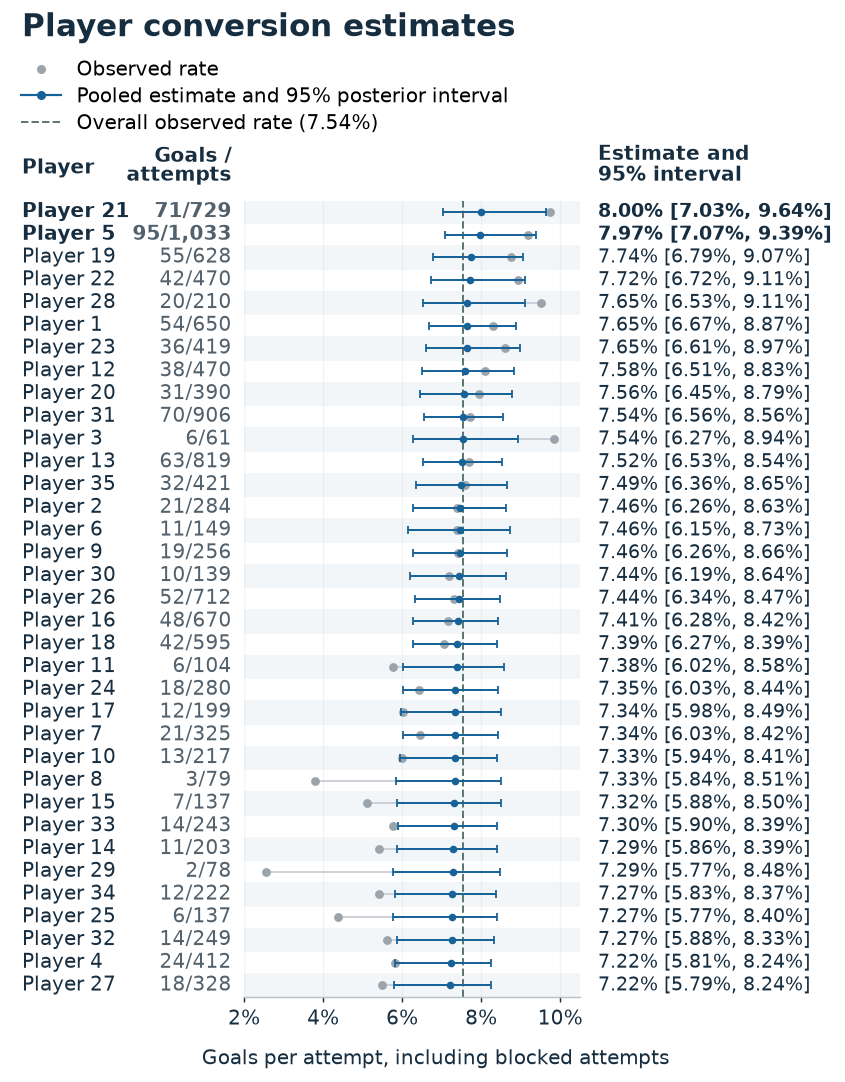

In [18]:
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
INK, BLUE, GRAY = '#172E40', '#176399', '#9BA4AA'
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,
                     'axes.spines.top':False,'axes.spines.right':False,
                     'axes.spines.left':True,'axes.spines.bottom':True,
                     'axes.labelcolor':INK,'xtick.color':INK,'ytick.color':INK})
data = private_players.rename(columns={'estimate':'pooled_no_season_mean',
                                      'lower':'pooled_no_season_q025',
                                      'upper':'pooled_no_season_q975'}).copy()
data = data.sort_values('pooled_no_season_mean', ascending=False).reset_index(drop=True)
observed = data.goals.sum() / data.attempts.sum()
width, height = 468, 600
fig = plt.figure(figsize=(width / 72, height / 72))
# These coordinates are points on the final document page.
left, bottom, chart_width, chart_height = 128, 48, 186, 441
ax = fig.add_axes([left/width, bottom/height, chart_width/width, chart_height/height])
y = np.arange(len(data))
for k in y[::2]:
    ax.axhspan(k-.49, k+.49, color='#F2F6F8', zorder=0)
for k, row in data.iterrows():
    ax.plot([row.raw_rate, row.pooled_no_season_mean], [k, k],
            color='#C8CFD4', lw=1, zorder=1)
ax.scatter(data.raw_rate, y, color=GRAY, s=15, zorder=3)
ax.errorbar(data.pooled_no_season_mean, y,
            xerr=np.array([data.pooled_no_season_mean-data.pooled_no_season_q025,
                           data.pooled_no_season_q975-data.pooled_no_season_mean]),
            fmt='o', ms=3.2, color=BLUE, elinewidth=1.1, capsize=2.2, zorder=4)
ax.axvline(observed, color='#5D776F', lw=1.1, ls='--', zorder=2)
ax.set_ylim(len(data)-.5, -.5)
ax.set_xlim(.02, .105)
ax.set_xticks([.02, .04, .06, .08, .10])
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_yticks([])
ax.tick_params(axis='x', length=3, pad=4)
ax.grid(axis='x', alpha=.13)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#B8C1C7')
for k, row in data.iterrows():
    yy = (bottom + chart_height * (1 - (k+.5)/len(data))) / height
    weight = 'bold' if row.shooter_id in (5, 21) else 'normal'
    fig.text(5/width, yy, f'Player {int(row.shooter_id)}', ha='left', va='center',
             fontsize=11, color=INK, weight=weight)
    fig.text(121/width, yy, f'{int(row.goals)}/{int(row.attempts):,}',
             ha='right', va='center', fontsize=11, color='#53616C', weight=weight)
    fig.text(324/width, yy,
             f'{row.pooled_no_season_mean:.2%} [{row.pooled_no_season_q025:.2%}, {row.pooled_no_season_q975:.2%}]',
             ha='left', va='center', fontsize=10.7, color=INK, weight=weight)
fig.text(5/width, 580/height, 'Player conversion estimates', fontsize=17,
         weight='bold', color=INK, va='baseline')
handles = [Line2D([0], [0], marker='o', color=GRAY, lw=0, markersize=4,
                  label='Observed rate'),
           Line2D([0], [0], marker='o', color=BLUE, lw=1.2, markersize=4,
                  label='Pooled estimate and 95% posterior interval'),
           Line2D([0], [0], color='#5D776F', ls='--', lw=1.1,
                  label=f'Overall observed rate ({observed:.2%})')]
fig.legend(handles=handles, loc='upper left', bbox_to_anchor=(0, 571/height),
           frameon=False, fontsize=11, labelspacing=.35, borderaxespad=0)
fig.text(5/width, 504/height, 'Player', fontsize=11, color=INK, weight='bold')
fig.text(121/width, 500/height, 'Goals /\nattempts', ha='right',
         fontsize=11, color=INK, weight='bold', linespacing=1.05)
fig.text(324/width, 500/height, 'Estimate and\n95% interval', ha='left',
         fontsize=11, color=INK, weight='bold', linespacing=1.05)
fig.text(.5, 8/height, 'Goals per attempt, including blocked attempts',
         ha='center', va='bottom', fontsize=11, color=INK)

fig.savefig(OUTPUT/'player_conversion_estimates.png',dpi=450,facecolor='white')
display(fig)
plt.close(fig)


## Variation relative to NHL forwards

Match the 35 cleaned take-home attempt counts to 35 distinct NHL forwards with sufficient 2021–22 through 2024–25 cumulative attempts. Assign counts largest first; select uniformly among eligible remaining players, then sample goals without replacement from that player's observed attempts. Repeat 20,000 times. The variation statistic is Pearson dispersion,
\[
D=\frac{1}{K-1}\sum_i\frac{(G_i-N_i\hat p)^2}{N_i\hat p(1-\hat p)},\qquad \hat p=\frac{\sum_iG_i}{\sum_iN_i}.
\]
The reported fraction compares observed count variation under this finite-history sampling scheme. A saved random-generator state starts the exact forward sample used in the document; the notebook computes every selected identity and resampled goal count anew.


In [19]:
import json

def player_dispersion(goals, attempts):
    goals, attempts = np.asarray(goals), np.asarray(attempts)
    rate = goals.sum(axis=-1)/attempts.sum()
    return np.sum((goals-attempts*rate[...,None])**2/(attempts*rate[...,None]*(1-rate[...,None])),axis=-1)

matched_targets = private_counts.sort_values(["attempts","player_id"],ascending=[False,True])
matched_n = matched_targets.attempts.to_numpy(dtype=int)
matched_source = nhl_four_year.sort_values("player_id")
source_n = matched_source.attempts.to_numpy(dtype=int)
source_g = matched_source.goals.to_numpy(dtype=int)
matched_rng = np.random.default_rng()
matched_rng.bit_generator.state = json.loads((NHL_INPUT / "nhl_match_rng.json").read_text())
matched_picks = np.empty((20000,len(matched_n)),dtype=int)
for column, attempts in enumerate(matched_n):
    eligible = np.flatnonzero(source_n>=attempts)
    picked = matched_rng.choice(eligible,size=20000)
    if column:
        collisions = np.any(picked[:,None]==matched_picks[:,:column],axis=1)
        while collisions.any():
            picked[collisions] = matched_rng.choice(eligible,size=int(collisions.sum()))
            collisions = np.any(picked[:,None]==matched_picks[:,:column],axis=1)
    matched_picks[:,column] = picked
matched_goals = matched_rng.hypergeometric(source_g[matched_picks],source_n[matched_picks]-source_g[matched_picks],matched_n[None,:])
nhl_matched_variation = player_dispersion(matched_goals,matched_n)/(len(matched_n)-1)
takehome_variation = float(player_dispersion(matched_targets.goals.to_numpy(),matched_n)/(len(matched_n)-1))
matched_fraction = float(np.mean(nhl_matched_variation<=takehome_variation))
print(f"Groups with variation at most the synthetic dataset: {matched_fraction:.1%} ({int(np.sum(nhl_matched_variation<=takehome_variation)):,} / 20,000)")


Groups with variation at most the synthetic dataset: 1.6% (315 / 20,000)


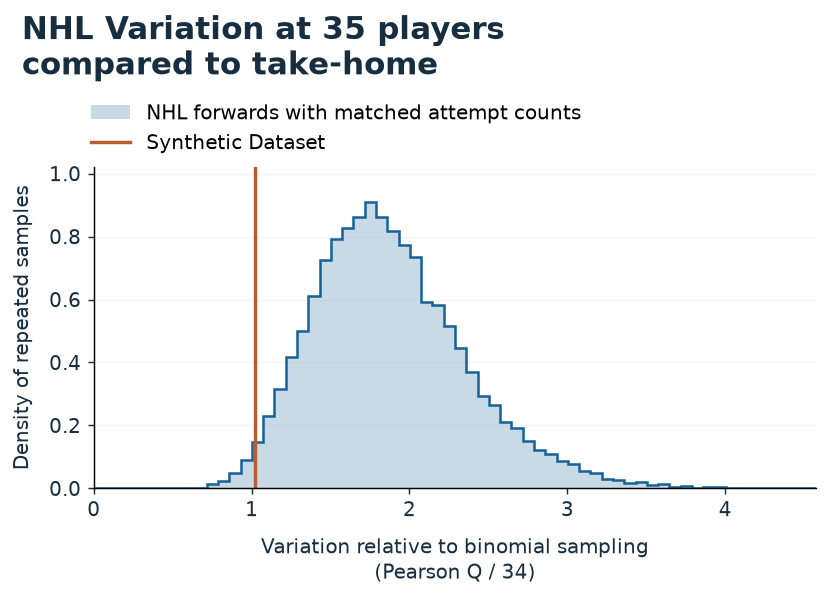

In [20]:
INK, BLUE, ORANGE = '#172E40', '#176399', '#B75D31'
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,
                     'axes.spines.top':False,'axes.spines.right':False,
                     'axes.spines.left':True,'axes.labelcolor':INK,'xtick.color':INK,'ytick.color':INK})
width, height = 468, 342
fig, ax = plt.subplots(figsize=(width/72, height/72))
fig.subplots_adjust(left=.125, right=.98, top=.70, bottom=.18)
bins = np.linspace(0, max(4.3, float(nhl_matched_variation.max())+.05), 65)
ax.hist(nhl_matched_variation, bins=bins, density=True, histtype='stepfilled', color=BLUE, alpha=.23,
        label='NHL forwards with matched attempt counts')
ax.hist(nhl_matched_variation, bins=bins, density=True, histtype='step', color=BLUE, lw=1.4)
ax.axvline(takehome_variation, color=ORANGE, lw=1.9, label='Synthetic Dataset')
ax.set_xlim(0, max(4.3, float(nhl_matched_variation.max())+.05))
ax.set_ylim(0, 1.02)
ax.set_xlabel('Variation relative to binomial sampling\n(Pearson Q / 34)', labelpad=8, linespacing=1.25)
ax.set_ylabel('Density of repeated samples', labelpad=9)
ax.grid(axis='y', alpha=.12)
fig.text(.04, .95, 'NHL Variation at 35 players\ncompared to take-home',
         fontsize=17, fontweight='bold', color=INK, va='top', linespacing=1.15)
fig.legend(*ax.get_legend_handles_labels(), loc='upper left',
           bbox_to_anchor=(.112, .815), frameon=False, fontsize=11,
           borderaxespad=0, labelspacing=.5)

fig.savefig(OUTPUT / 'nhl_variation_35_players.png',dpi=450,facecolor='white')
plt.show()


### Probability of detecting between-player variation

For each player count, repeat the 35-player take-home exposure pattern, preserving attempts per player. All scenarios share the take-home marginal mean conversion rate. Player log-odds vary normally with dispersion fixed at the posterior median from either the take-home fit or the four-year NHL forward fit. Calibrate a 5% detection threshold using 20,000 common-probability simulations, then estimate power from 10,000 simulations per dispersion scenario. These are conditional detection probabilities, with total attempts increasing alongside player count.


In [21]:
private_power_counts = private_counts.sort_values("player_id")
power_n0 = private_power_counts.attempts.to_numpy(dtype=int)
power_mean = private_power_counts.goals.sum()/power_n0.sum()
power_tau = {"takehome":float(np.median(private_fit["tau"])),
             "nhl":float(np.median(nhl_fits["Four earlier seasons"]["tau"]))}
power_nodes, power_weights = hermgauss(60)
power_weights /= np.sqrt(np.pi)
power_alpha = {name:float(brentq(lambda a:np.dot(power_weights,expit(a+np.sqrt(2)*tau*power_nodes))-power_mean,-10,5))
               for name,tau in power_tau.items()}

def simulate_player_variation(attempts,tau,alpha,replicates,seed):
    rng = np.random.default_rng(seed)
    result = []
    for offset in range(0,replicates,500):
        count = min(500,replicates-offset)
        probability = power_mean if tau==0 else expit(alpha+tau*rng.normal(size=(count,len(attempts))))
        goals = rng.binomial(attempts,probability,size=(count,len(attempts))).astype(float)
        # Algebraically equivalent Pearson Q, preserving the original simulation's arithmetic.
        p = goals.sum(axis=-1)/attempts.sum()
        q = ((goals**2/attempts).sum(axis=-1)-goals.sum(axis=-1)**2/attempts.sum())/(p*(1-p))
        result.append(q)
    return np.concatenate(result)

power_rows = []
for players in [35,70,140,350,700]:
    attempts = np.tile(power_n0,players//len(power_n0))
    null = simulate_player_variation(attempts,0.,0.,20000,100000+players)
    critical = float(np.quantile(null,.95))
    row = {"Player count":players}
    for name, original_scenario_index, title in [("nhl",2,"At NHL variation"),("takehome",1,"At take-home variation")]:
        q = simulate_player_variation(attempts,power_tau[name],power_alpha[name],10000,
                                      200000+1000*original_scenario_index+players)
        row[title] = float(np.mean(q>critical))
    power_rows.append(row)
player_count_power = pd.DataFrame(power_rows)
player_count_power.to_csv(OUTPUT / "player_count_detection_power.csv",index=False)
display(player_count_power.style.format({column:(lambda value: ">99%" if value>.99 else f"{value:.0%}")
                                         for column in ["At NHL variation","At take-home variation"]}).hide(axis="index"))


Player count,At NHL variation,At take-home variation
35,92%,14%
70,>99%,18%
140,>99%,27%
350,>99%,46%
700,>99%,72%
